# Final Sentiment Experiment

I wanted to see if I could improve sentiment without changing the network. I tried adding a little noise to the training features and a small adjustment to the neutral score. I kept the image predictions from V8.

First, I imported the libraries and the same training functions used by NN V3.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

project_root = Path.cwd()
if not (project_root / 'src').is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from src.data_loader import load_task, split_train_val, standardize
from src.neural_net import ModelConfig, train_model, predict_probabilities

result_dir = project_root / 'results/sentiment'
result_dir.mkdir(parents=True, exist_ok=True)
device = torch.device('cpu')
torch.set_num_threads(1)
print('PyTorch:', torch.__version__, 'device:', device)
config = ModelConfig(hidden_sizes=(256, 64), activation='relu', optimizer='adam',
    learning_rate=0.0001, batch_size=128, dropout=0.5, weight_decay=0,
    early_stopping=True, patience=6)

PyTorch: 2.5.1+cpu device: cpu


I used the original split and calculated the standardization values from the training examples only.

In [2]:
X, y, X_test, test_ids = load_task('sentiment')
X_train, X_val, y_train, y_val = split_train_val(X, y, val_fraction=0.2, seed=42)
assert X.shape == (12000, 768) and X_test.shape == (5000, 768)
assert X_train.shape == (9600, 768) and X_val.shape == (2400, 768)
X_train_scaled, X_val_scaled = standardize(X_train, X_val)
old_validation = pd.read_csv(result_dir / 'nn_v3_validation.csv')
assert np.array_equal(old_validation.validation_index, np.arange(2400))
assert np.array_equal(old_validation.actual_label, y_val)
assert np.array_equal(np.bincount(y_val), [800, 800, 800])
saved_correct = int((old_validation.predicted_label.to_numpy() == y_val).sum())
image_validation = pd.read_csv(project_root / 'results/model_comparison/knn_vs_voting_v8_image_validation.csv')
image_accuracy = float((image_validation.predicted_label == image_validation.actual_label).mean())
v8_submission = pd.read_csv(project_root / 'submission/model_combinations/submission_knn_vs_voting_v8.csv')
sample = pd.read_csv(project_root / 'data/raw/sample_submission.csv')
assert v8_submission.columns.tolist() == sample.columns.tolist() == ['id', 'label']
assert len(v8_submission) == len(sample) == 10000 and v8_submission.id.is_unique and sample.id.is_unique
assert set(v8_submission.id) == set(sample.id) and not v8_submission.isna().any().any()
print('Original NN V3 sentiment:', saved_correct, '/', len(y_val))
print('V8 image validation accuracy:', image_accuracy)

Original NN V3 sentiment: 1639 / 2400
V8 image validation accuracy: 0.59675


I first trained A with the original NN V3 settings and seed, then compared its result with the saved predictions.

In [3]:
baseline_run = train_model(X_train_scaled, y_train, output_size=3, config=config,
    epochs=20, seed=45, device=device, validation_features=X_val_scaled,
    validation_labels=y_val, early_stopping=True)
baseline_probabilities = predict_probabilities(baseline_run.model, X_val_scaled, config.batch_size, device)
baseline_predictions = baseline_probabilities.argmax(axis=1)
baseline_correct = int((baseline_predictions == y_val).sum())
print('A baseline:', baseline_correct, '/', len(y_val), 'best epoch:', baseline_run.best_epoch)
print('Changed labels from saved NN V3:', int((baseline_predictions != old_validation.predicted_label.to_numpy()).sum()))
if baseline_correct != saved_correct:
    print('Baseline difference from saved NN V3:', baseline_correct - saved_correct, 'correct predictions.')

A baseline: 1638 / 2400 best epoch: 12
Changed labels from saved NN V3: 70
Baseline difference from saved NN V3: -1 correct predictions.


When I reran the baseline, the results were slightly different from the saved ones, so I used the new predictions to compare the methods. For B, I added noise to the standardized training features, but left the validation features unchanged.

In [4]:
rng = np.random.default_rng(42)
X_train_noisy = X_train_scaled + rng.normal(0, 0.03, X_train_scaled.shape).astype(np.float32)
noise_run = train_model(X_train_noisy, y_train, output_size=3, config=config,
    epochs=20, seed=45, device=device, validation_features=X_val_scaled,
    validation_labels=y_val, early_stopping=True)
noise_probabilities = predict_probabilities(noise_run.model, X_val_scaled, config.batch_size, device)
noise_predictions = noise_probabilities.argmax(axis=1)
print('B training noise:', int((noise_predictions == y_val).sum()), '/', len(y_val),
      'best epoch:', noise_run.best_epoch)

B training noise: 1641 / 2400 best epoch: 12


For C and D, I added 0.02 to the neutral score when choosing the label. C uses A's model and D uses B's model, so these two checks don't need another training run.

In [5]:
baseline_scores = baseline_probabilities.copy()
baseline_scores[:, 1] += 0.02
noise_scores = noise_probabilities.copy()
noise_scores[:, 1] += 0.02
predictions = {'A': baseline_predictions, 'B': noise_predictions,
               'C': baseline_scores.argmax(axis=1), 'D': noise_scores.argmax(axis=1)}
approaches = {'A': 'Baseline', 'B': 'Training noise',
              'C': 'Neutral adjustment', 'D': 'Noise + neutral adjustment'}
training_runs = {'A': baseline_run, 'B': noise_run, 'C': baseline_run, 'D': noise_run}

I compared all four approaches across the three classes and both halves of the same validation split. I chose the highest overall accuracy, with A, B, C and D winning ties in that order.

In [6]:
rows = []
original_correct = old_validation.predicted_label.to_numpy() == y_val
for method in ['A', 'B', 'C', 'D']:
    labels = predictions[method]
    correct = labels == y_val
    row = {'method': method, 'approach': approaches[method], 'correct_count': int(correct.sum()),
           'validation_samples': len(y_val), 'validation_accuracy': float(correct.mean()),
           'best_epoch': training_runs[method].best_epoch, 'training_run': 'B' if method in ['B', 'D'] else 'A',
           'training_noise': method in ['B', 'D'], 'neutral_adjustment': method in ['C', 'D']}
    for class_label in [0, 1, 2]:
        row[f'class_{class_label}_accuracy'] = float(correct[y_val == class_label].mean())
    row['first_half_correct'] = int(correct[:1200].sum())
    row['last_half_correct'] = int(correct[1200:].sum())
    row['corrected_mistakes'] = int((~original_correct & correct).sum())
    row['new_mistakes'] = int((original_correct & ~correct).sum())
    row['changed_labels'] = int((labels != old_validation.predicted_label.to_numpy()).sum())
    row['combined_validation_accuracy'] = (image_accuracy + row['validation_accuracy']) / 2
    rows.append(row)
summary = pd.DataFrame(rows)
selected = summary.loc[summary.validation_accuracy.idxmax()]
selected_method = selected['method']
summary['selected'] = summary.method == selected_method
summary.to_csv(result_dir / 'sentiment_final_summary.csv', index=False)
print(summary[['method', 'approach', 'correct_count', 'validation_accuracy',
    'class_0_accuracy', 'class_1_accuracy', 'class_2_accuracy', 'best_epoch']].to_string(index=False))
for row in rows:
    print(f"{row['method']}: first half={row['first_half_correct']}/1200 ({row['first_half_correct']/1200:.3%}), "
          f"last half={row['last_half_correct']}/1200 ({row['last_half_correct']/1200:.3%}); "
          f"corrected={row['corrected_mistakes']}, new mistakes={row['new_mistakes']}")
selected_predictions = predictions[selected_method]
pd.DataFrame({'validation_index': np.arange(len(y_val)), 'actual_label': y_val,
    'predicted_label': selected_predictions}).to_csv(result_dir / 'sentiment_final_validation.csv', index=False)
combined_accuracy = float(selected['combined_validation_accuracy'])
print('Selected:', selected_method, approaches[selected_method])
print('Additional correct sentiment examples:', int(selected['correct_count']) - saved_correct)
print('Combined validation accuracy:', combined_accuracy)
if int(selected['correct_count']) <= baseline_correct:
    print('None of the new approaches improved the baseline.')

method                   approach  correct_count  validation_accuracy  class_0_accuracy  class_1_accuracy  class_2_accuracy  best_epoch
     A                   Baseline           1638             0.682500           0.78750           0.54875           0.71125          12
     B             Training noise           1641             0.683750           0.79000           0.54875           0.71250          12
     C         Neutral adjustment           1638             0.682500           0.78375           0.55875           0.70500          12
     D Noise + neutral adjustment           1636             0.681667           0.78125           0.56125           0.70250          12
A: first half=818/1200 (68.167%), last half=820/1200 (68.333%); corrected=29, new mistakes=30
B: first half=821/1200 (68.417%), last half=820/1200 (68.333%); corrected=30, new mistakes=28
C: first half=818/1200 (68.167%), last half=820/1200 (68.333%); corrected=33, new mistakes=34
D: first half=815/1200 (67.917%), last

I plotted the four sentiment accuracies to compare the small differences.

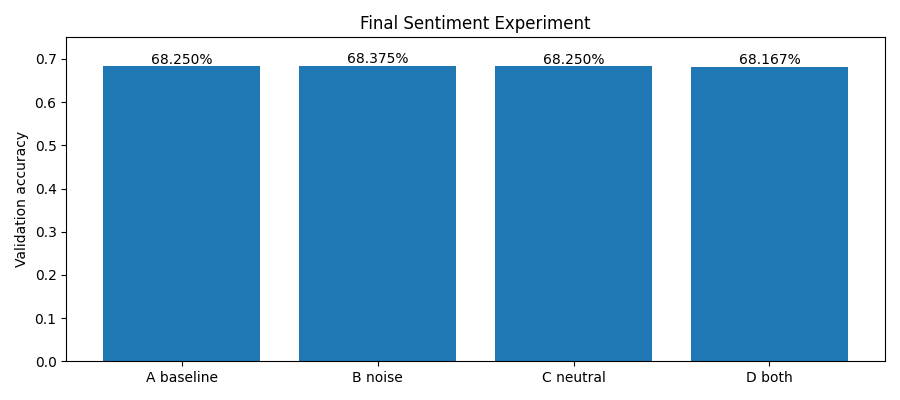

In [7]:
plt.figure(figsize=(9, 4))
plt.bar(['A baseline', 'B noise', 'C neutral', 'D both'], summary.validation_accuracy)
for position, accuracy in enumerate(summary.validation_accuracy):
    plt.text(position, accuracy + 0.006, f'{accuracy:.3%}', ha='center')
plt.ylabel('Validation accuracy')
plt.title('Final Sentiment Experiment')
plt.ylim(0, 0.75)
plt.tight_layout()
plt.savefig(result_dir / 'sentiment_final_accuracy.png')
plt.show()

I trained the selected approach on all 12000 labeled sentiment examples, using its best validation epoch. I calculated new standardization values from all the labeled data and kept the test features clean.

In [8]:
X, y, X_test, test_ids = load_task('sentiment')
X_all_scaled, X_test_scaled = standardize(X, X_test)
full_training_features = X_all_scaled
if bool(selected['training_noise']):
    rng = np.random.default_rng(42)
    full_training_features = X_all_scaled + rng.normal(0, 0.03, X_all_scaled.shape).astype(np.float32)
selected_epochs = int(selected['best_epoch'])
final_run = train_model(full_training_features, y, output_size=3, config=config,
    epochs=selected_epochs, seed=145, device=device)
test_probabilities = predict_probabilities(final_run.model, X_test_scaled, config.batch_size, device)
test_scores = test_probabilities.copy()
if bool(selected['neutral_adjustment']):
    test_scores[:, 1] += 0.02
test_predictions = test_scores.argmax(axis=1)
assert len(test_predictions) == 5000 and ((test_predictions >= 0) & (test_predictions <= 2)).all()
print('Full-data sentiment training examples:', len(y), 'epochs:', selected_epochs, 'seed:', 145)

Full-data sentiment training examples: 12000 epochs: 12 seed: 145


I kept the 5000 image predictions from V8 and matched them with the new sentiment predictions by ID before saving the Kaggle CSV.

In [9]:
_, _, _, image_test_ids = load_task('image')
image_predictions = pd.DataFrame({'id': image_test_ids}).merge(v8_submission,
    on='id', how='left', sort=False, validate='one_to_one')
sentiment_predictions = pd.DataFrame({'id': test_ids, 'label': test_predictions})
assert len(image_predictions) == len(sentiment_predictions) == 5000
assert set(image_test_ids).isdisjoint(set(test_ids)) and set(sample.id) == set(image_test_ids) | set(test_ids)
all_predictions = pd.concat([image_predictions, sentiment_predictions], ignore_index=True)
submission = sample[['id']].merge(all_predictions, on='id', how='left', sort=False, validate='one_to_one')
assert submission.columns.tolist() == ['id', 'label'] and len(submission) == 10000
assert submission.id.tolist() == sample.id.tolist() and submission.id.is_unique and not submission.isna().any().any()
assert pd.api.types.is_integer_dtype(submission.label)
is_image = submission.id.isin(image_test_ids)
is_sentiment = submission.id.isin(test_ids)
assert is_image.sum() == is_sentiment.sum() == 5000
assert submission.loc[is_image, 'label'].between(0, 49).all() and submission.loc[is_sentiment, 'label'].between(0, 2).all()
previous = sample[['id']].merge(v8_submission, on='id', how='left', sort=False, validate='one_to_one')
changed = submission.label != previous.label
changed_images = int((changed & is_image).sum())
changed_sentiment = int((changed & is_sentiment).sum())
assert changed_images == 0
submission_dir = project_root / 'submission/model_combinations'
submission_dir.mkdir(parents=True, exist_ok=True)
submission_path = submission_dir / 'submission_sentiment_final.csv'
submission.to_csv(submission_path, index=False)
pd.testing.assert_frame_equal(pd.read_csv(submission_path), submission)
print('Saved', len(submission), 'predictions to', submission_path.relative_to(project_root))
print('Changed image predictions compared with V8:', changed_images)
print('Changed sentiment predictions compared with V8:', changed_sentiment)
if changed_sentiment == 0:
    print('This duplicates V8, so there is no reason to upload it again.')
else:
    print('The new file is a distinct sentiment candidate.')

Saved 10000 predictions to submission/model_combinations/submission_sentiment_final.csv
Changed image predictions compared with V8: 0
Changed sentiment predictions compared with V8: 171
The new file is a distinct sentiment candidate.


Training noise got 1641/2400 sentiment examples correct (68.375%), 2 more than the saved NN V3 result and 3 more than my baseline rerun. The difference was small on the same validation split used for earlier choices. I kept the V8 image predictions and will check whether the new sentiment predictions help on Kaggle.